# Heart Disease Classification — Exploratory Data Analysis

**Dataset:** UCI Cleveland Heart Disease  
**Objective:** Explore the data and understand factors associated with heart disease.

The original target ranges from 0 to 4. For this project's binary classification task, target 0 means no disease and values greater than 0 mean disease present.

This analysis is educational and is not intended for clinical diagnosis.


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"
df = pd.read_csv(DATA_PATH, na_values="?")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Dataset structure and summary

In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nSummary statistics:")
display(df.describe().T)


Rows: 303
Columns: 14

Data types:


,dtype
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Missing values and data quality

In [12]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print("Missing values by column:")
display(missing.to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())

df = df.dropna().copy()
df["target"] = (df["target"] > 0).astype(int)

print("Shape after dropping missing rows:", df.shape)
print("\nBinary target counts:")
display(df["target"].value_counts().sort_index().rename(
    index={0: "No disease", 1: "Disease present"}
).to_frame("count"))


Missing values by column:


,missing_count
ca,4
thal,2


Duplicate rows: 0
Shape after dropping missing rows: (297, 14)

Binary target counts:


,count
target,
No disease,160
Disease present,137


## 3. Target distribution

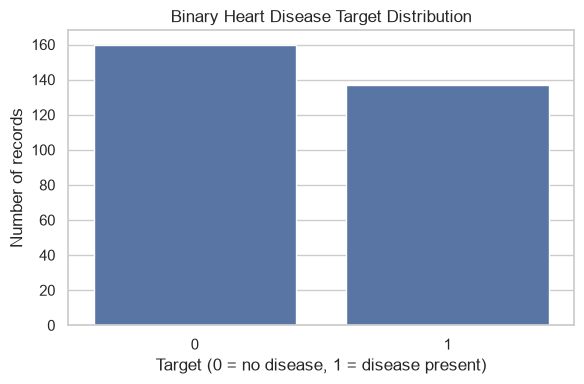

In [13]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Binary Heart Disease Target Distribution")
plt.xlabel("Target (0 = no disease, 1 = disease present)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


## 4. Feature distributions

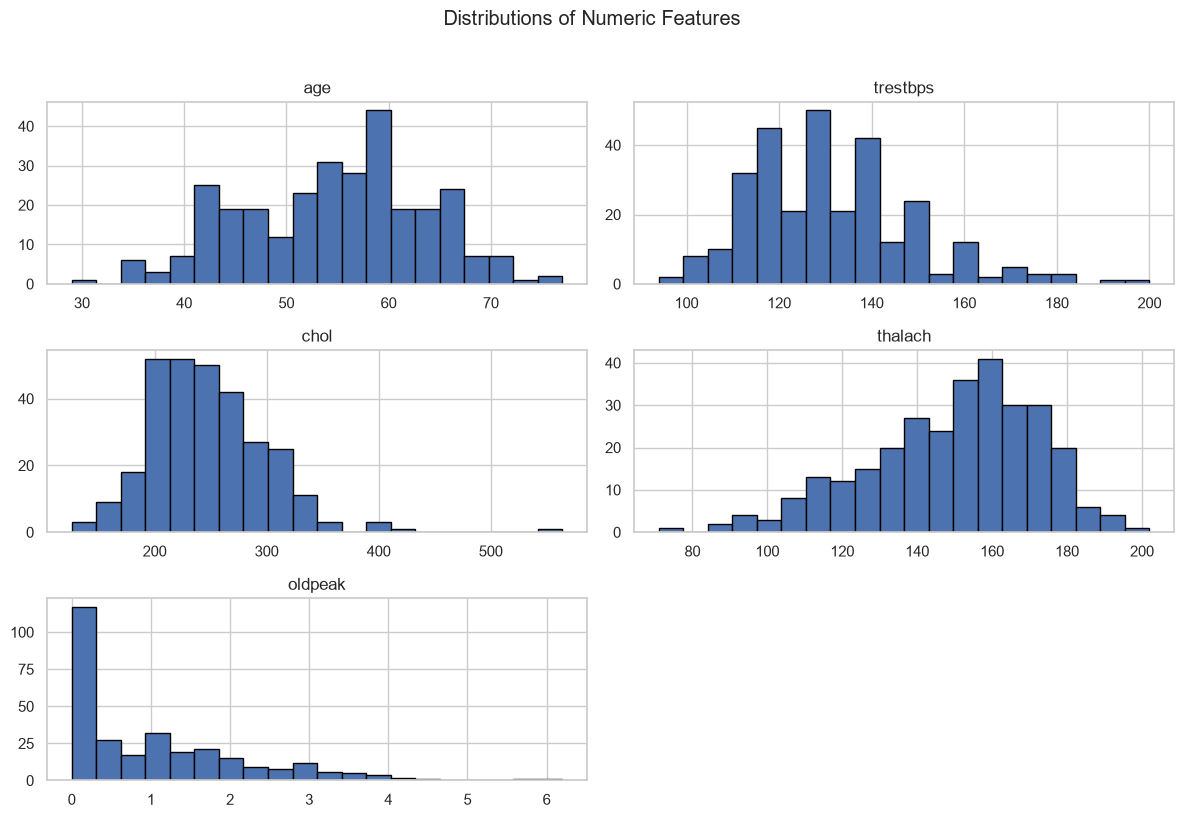

In [14]:
numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

df[numeric_features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()


## 5. Numeric features by target

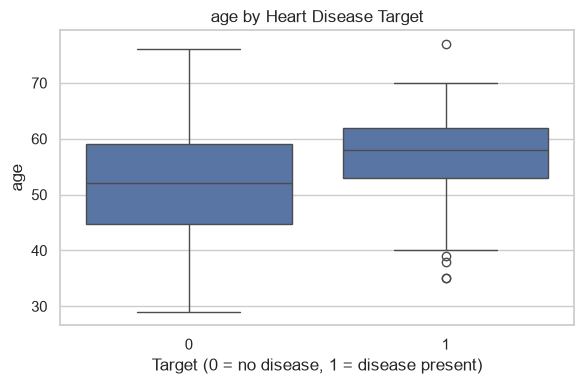

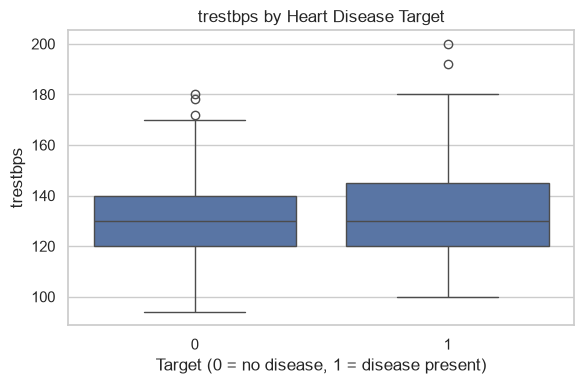

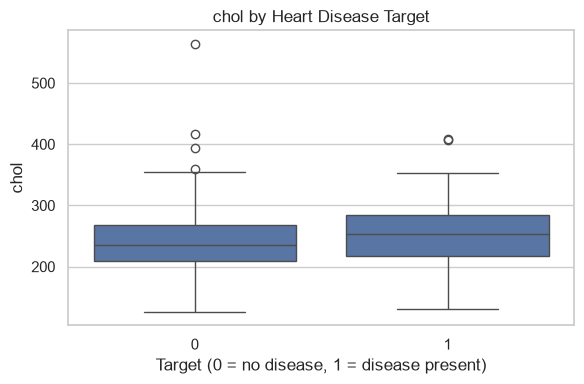

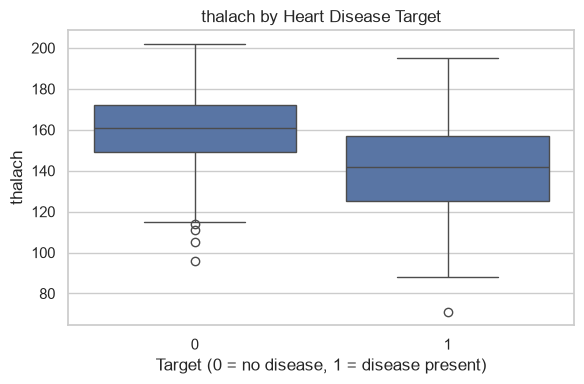

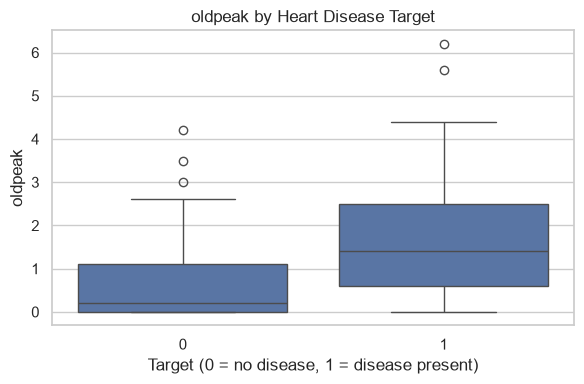

In [15]:
for feature in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="target", y=feature)
    plt.title(f"{feature} by Heart Disease Target")
    plt.xlabel("Target (0 = no disease, 1 = disease present)")
    plt.tight_layout()
    plt.show()


## 6. Correlation analysis

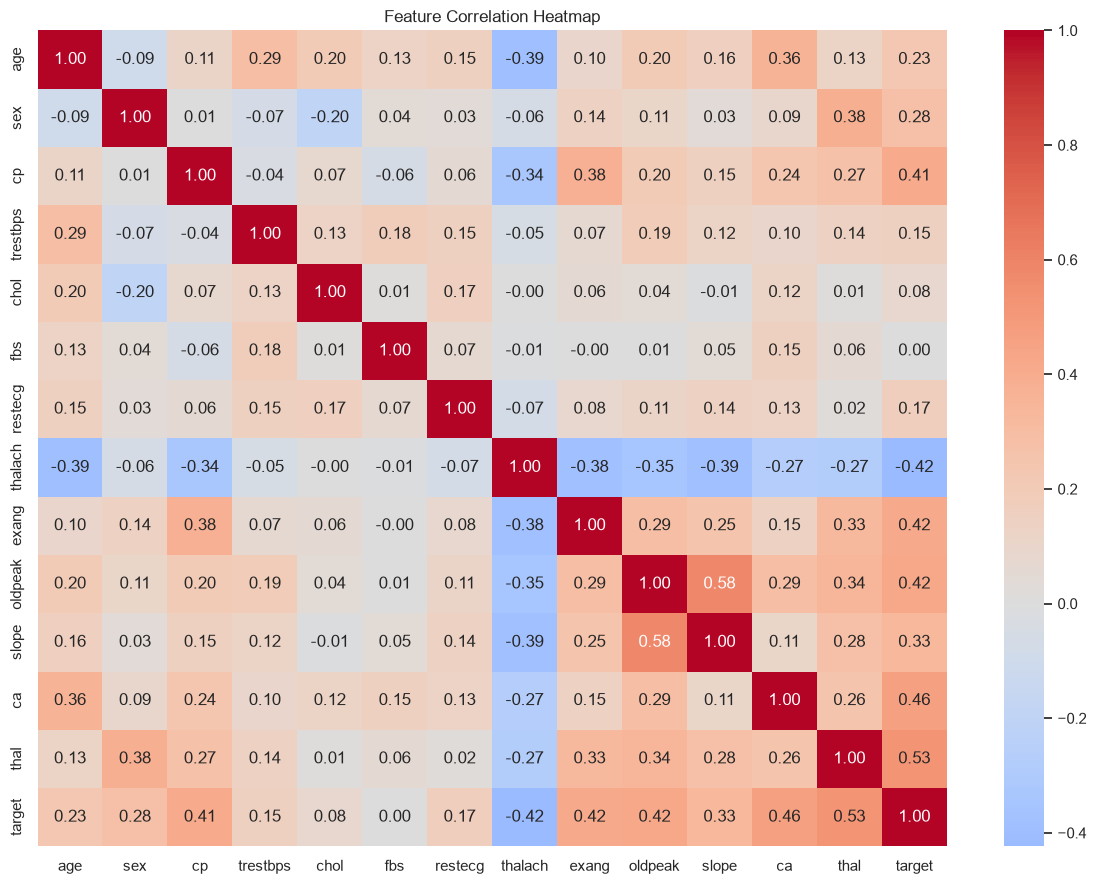

Features most correlated with the binary target:


,correlation_with_target
thal,0.526640
ca,0.463189
oldpeak,0.424052
thalach,-0.423817
exang,0.421355
cp,0.408945
slope,0.333049
sex,0.278467
age,0.227075
restecg,0.166343


In [16]:
plt.figure(figsize=(12, 9))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Features most correlated with the binary target:")
display(correlation["target"].drop("target").sort_values(
    key=abs, ascending=False
).to_frame("correlation_with_target"))


## 7. Categorical feature comparisons

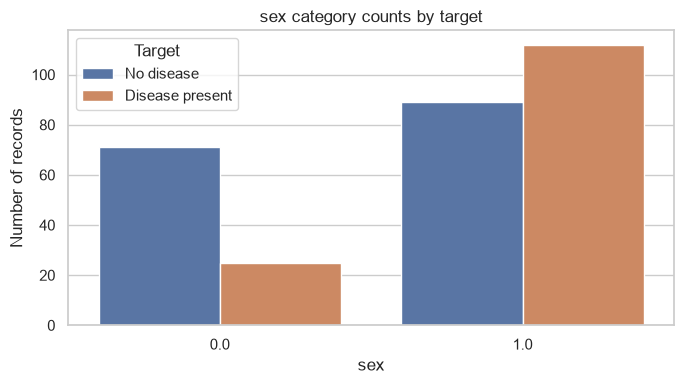

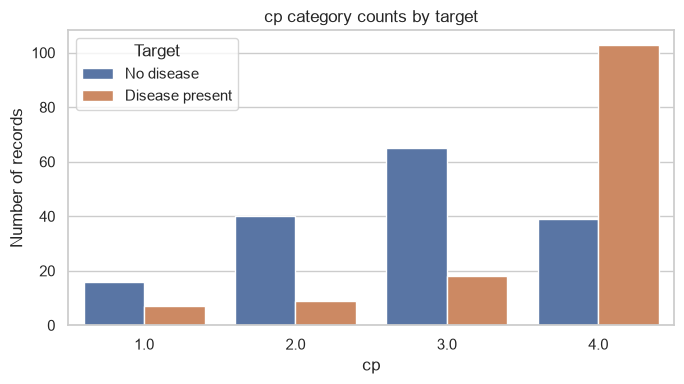

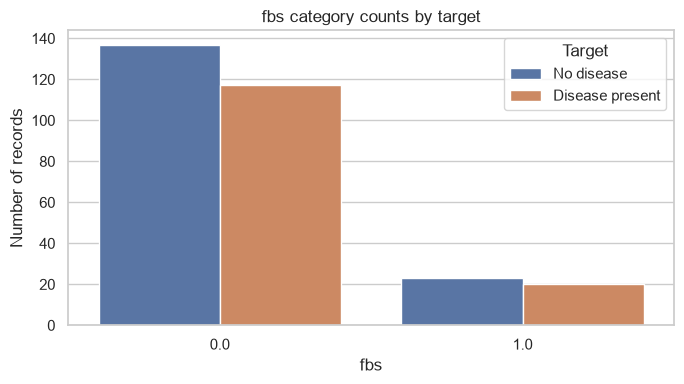

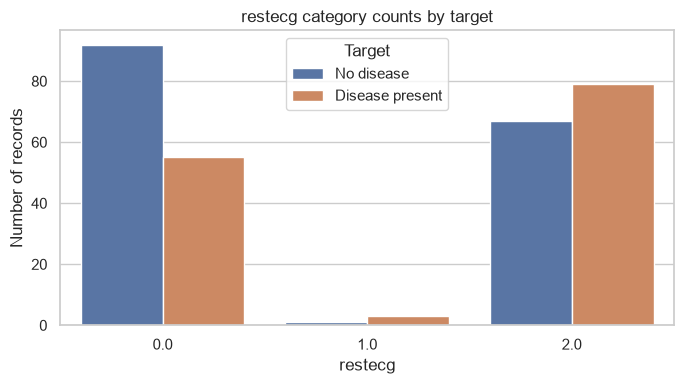

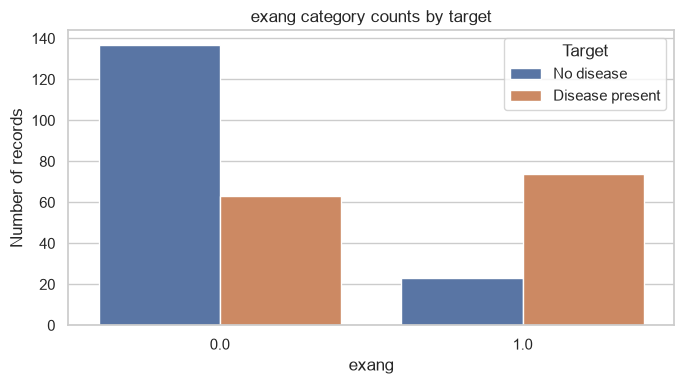

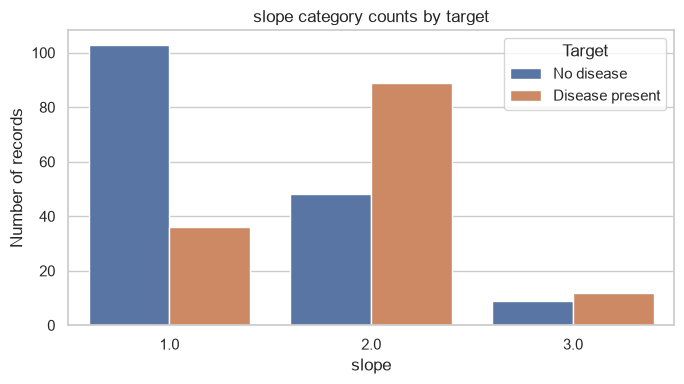

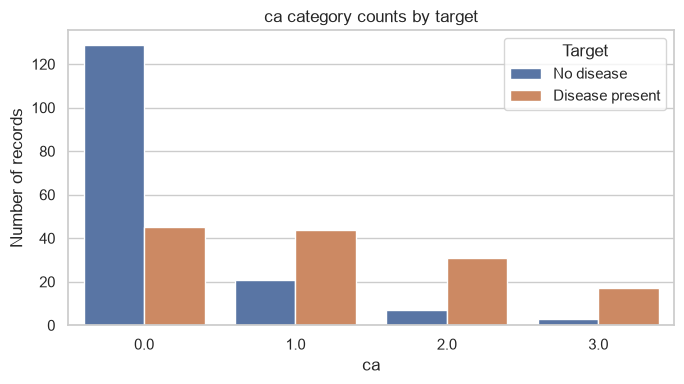

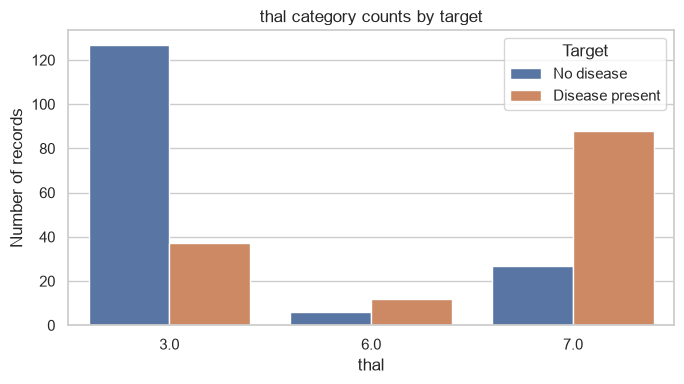

In [17]:
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

for feature in categorical_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=feature, hue="target")
    plt.title(f"{feature} category counts by target")
    plt.xlabel(feature)
    plt.ylabel("Number of records")
    plt.legend(title="Target", labels=["No disease", "Disease present"])
    plt.tight_layout()
    plt.show()


## 8. Key observations and conclusion

In [18]:
print(f"Records available after cleaning: {len(df)}")
print(f"Input features: {df.shape[1] - 1}")
print(f"Records with disease label 1: {(df['target'] == 1).sum()}")
print(f"Records with no-disease label 0: {(df['target'] == 0).sum()}")

print("\nAbsolute correlations with target (exploratory only):")
display(
    df.corr(numeric_only=True)["target"]
    .drop("target")
    .abs()
    .sort_values(ascending=False)
    .head(5)
    .to_frame("absolute_correlation")
)

print("\nConclusion:")
print("- The dataset contains clinical measurements and categorical attributes.")
print("- Missing values were removed here to match the project's data preparation step.")
print("- The original target was converted to binary labels for this classification project.")
print("- Correlations and plots describe associations, not causation or medical risk.")
print("- Model evaluation and cross-validation are required beyond EDA.")


Records available after cleaning: 297
Input features: 13
Records with disease label 1: 137
Records with no-disease label 0: 160

Absolute correlations with target (exploratory only):


,absolute_correlation
thal,0.526640
ca,0.463189
oldpeak,0.424052
thalach,0.423817
exang,0.421355



Conclusion:
- The dataset contains clinical measurements and categorical attributes.
- Missing values were removed here to match the project's data preparation step.
- The original target was converted to binary labels for this classification project.
- Correlations and plots describe associations, not causation or medical risk.
- Model evaluation and cross-validation are required beyond EDA.
